In [9]:
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Dense,Flatten,Embedding,SimpleRNN,LSTM,GRU,Input,Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.datasets import imdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [10]:
VOCAB_SIZE=10000
MAX_LEN = 200
RNN_UNITS=32
EMBEDDING_DIM=32

In [11]:
(x_train,y_train),(x_test,y_test) = imdb.load_data(num_words=VOCAB_SIZE)

x_train = pad_sequences(
    x_train,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)
x_test = pad_sequences(
    x_test,
    maxlen = MAX_LEN,
    padding='post',
    truncating='post'
)

In [18]:
model = Sequential([
    Embedding(input_dim=VOCAB_SIZE,output_dim=EMBEDDING_DIM,input_length=MAX_LEN),
    SimpleRNN(RNN_UNITS),
    Dropout(0.2),
    Dense(1,activation="sigmoid"),
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [19]:
model.compile(
    optimizer = 'adam',
    loss='binary_crossentropy',
    metrics=["accuracy"]
)

In [20]:
history = model.fit(x_train,y_train,epochs=5,batch_size=128,validation_split=0.2)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 17s 87ms/step - accuracy: 0.5113 - loss: 0.6950 - val_accuracy: 0.5186 - val_loss: 0.6922
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 13s 84ms/step - accuracy: 0.5871 - loss: 0.6754 - val_accuracy: 0.5136 - val_loss: 0.6946
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 21s 85ms/step - accuracy: 0.6625 - loss: 0.6073 - val_accuracy: 0.5130 - val_loss: 0.7236
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 13s 86ms/step - accuracy: 0.7323 - loss: 0.4917 - val_accuracy: 0.5070 - val_loss: 0.7985
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 13s 85ms/step - accuracy: 0.7828 - loss: 0.4064 - val_accuracy: 0.5108 - val_loss: 0.8704


Text(0, 0.5, 'Accuracy')

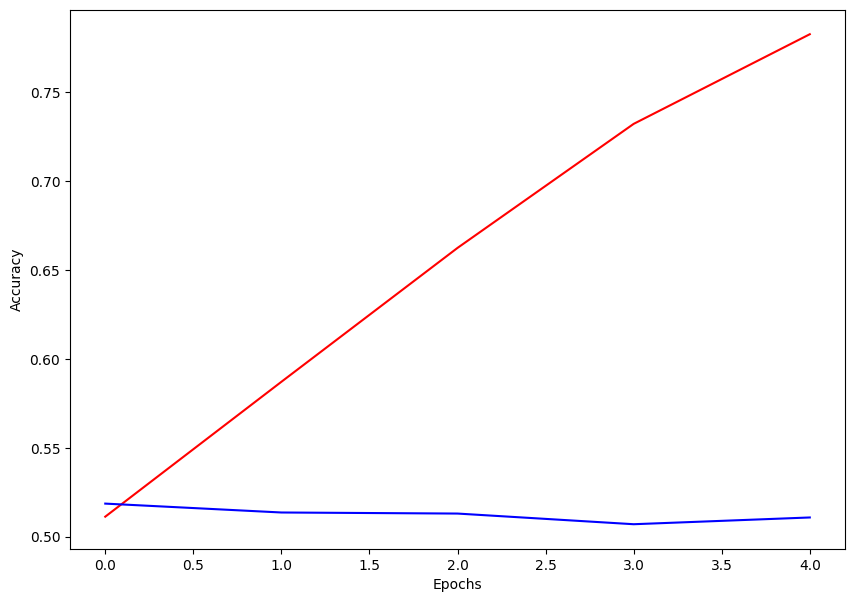

In [27]:
plt.figure(figsize=(10,7))
plt.plot(history.history["accuracy"],color='red',label="Training accuracy")
plt.plot(history.history["val_accuracy"],color='blue',label="Validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

Text(0, 0.5, 'loss')

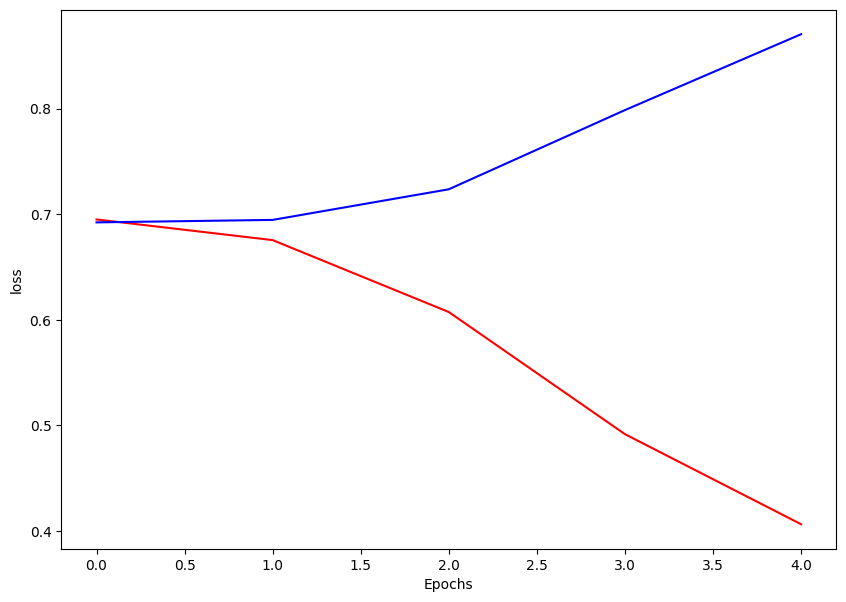

In [28]:
plt.figure(figsize=(10,7))
plt.plot(history.history["loss"],color='red',label="Training loss")
plt.plot(history.history["val_loss"],color='blue',label="Validation loss")
plt.xlabel("Epochs")
plt.ylabel("loss")

In [31]:
model_LSTM = Sequential([
    Embedding(input_dim=VOCAB_SIZE,output_dim=EMBEDDING_DIM,input_length=MAX_LEN),
    LSTM(RNN_UNITS),
    Dropout(0.2),
    Dense(1,activation="sigmoid"),
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [32]:
model_LSTM.compile(
    optimizer = 'adam',
    loss='binary_crossentropy',
    metrics=["accuracy"]
)

In [34]:
history_LSTM = model_LSTM.fit(x_train,y_train,epochs=5,batch_size=128,validation_split=0.2)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 27s 172ms/step - accuracy: 0.5524 - loss: 0.6766 - val_accuracy: 0.5350 - val_loss: 0.6790
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 26s 169ms/step - accuracy: 0.6039 - loss: 0.6565 - val_accuracy: 0.6074 - val_loss: 0.6612
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 40s 163ms/step - accuracy: 0.6458 - loss: 0.6348 - val_accuracy: 0.6042 - val_loss: 0.6471
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 26s 169ms/step - accuracy: 0.6280 - loss: 0.6418 - val_accuracy: 0.5444 - val_loss: 0.7451
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 40s 165ms/step - accuracy: 0.6388 - loss: 0.6298 - val_accuracy: 0.5812 - val_loss: 0.6598


Text(0, 0.5, 'Accuracy')

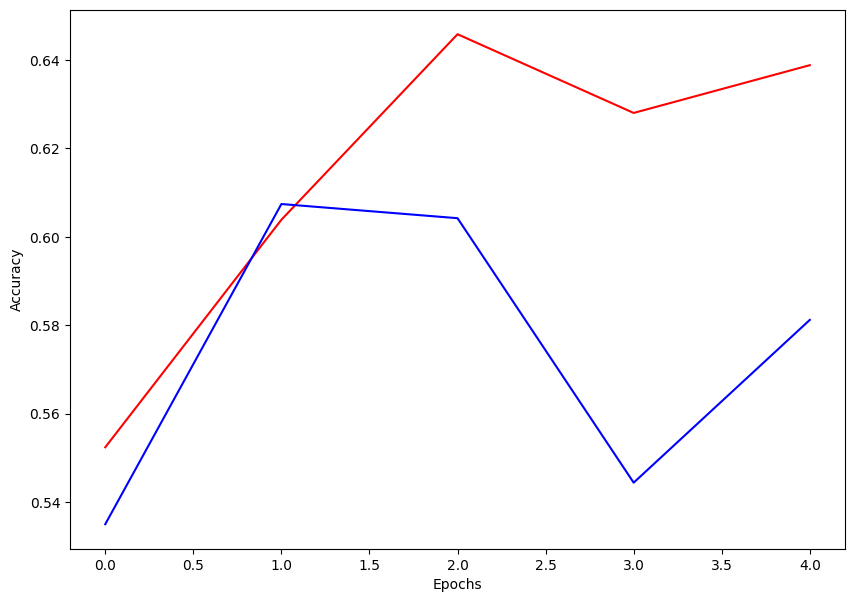

In [35]:
plt.figure(figsize=(10,7))
plt.plot(history_LSTM.history["accuracy"],color='red',label="Training accuracy")
plt.plot(history_LSTM.history["val_accuracy"],color='blue',label="Validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

Text(0, 0.5, 'loss')

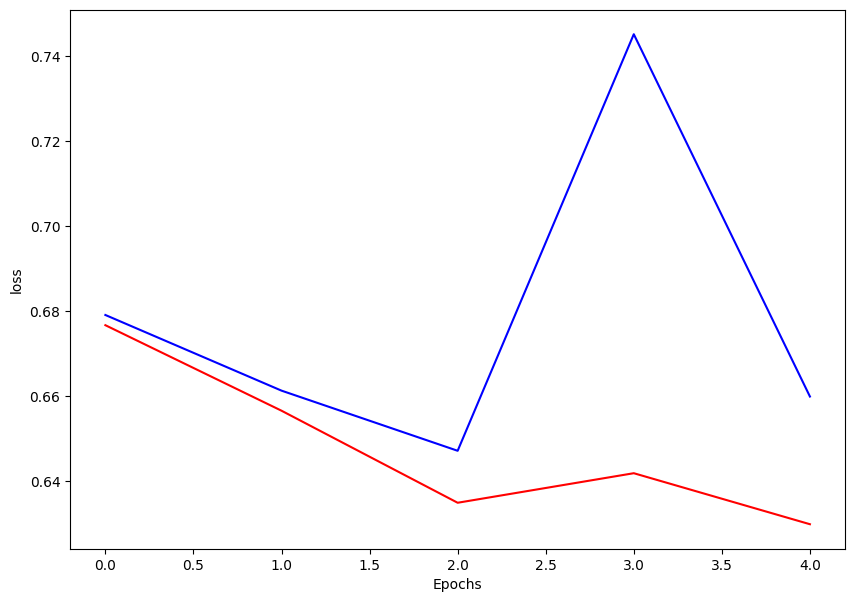

In [36]:
plt.figure(figsize=(10,7))
plt.plot(history_LSTM.history["loss"],color='red',label="Training loss")
plt.plot(history_LSTM.history["val_loss"],color='blue',label="Validation loss")
plt.xlabel("Epochs")
plt.ylabel("loss")

In [38]:
word_index = imdb.get_word_index()

word_index = {
    word: index+3 for word,index in word_index.items()
}

In [43]:
word_index["<PAD>"] = 0
word_index["<START>"] = 1
word_index["<UNK>"] = 2
word_index["<UNUSED"] = 3

def encode_review(review):
  encode_list = review.lower().split()
  encoded = []
  for word in review:
    word = word.strip(",.\?!""()[]{}")
    if word in word_index:
      encoded.append(word_index[word])
    else:
      encoded.append(2)

  encoded = pad_sequences(
      [encoded],
      maxlen=MAX_LEN,
      padding='post',
      truncating='post'
  )
  return encoded

<>:10: SyntaxWarning: invalid escape sequence '\?'
<>:10: SyntaxWarning: invalid escape sequence '\?'
/tmp/ipykernel_677/4004092283.py:10: SyntaxWarning: invalid escape sequence '\?'
  word = word.strip(",.\?!""()[]{}")


In [45]:
def predict_review(review):
  encoded_review = encode_review(review)
  predicted = model.predict(encoded_review)
  if predicted > 0.5:
    print("Positive")
  else:
    print("Negative")

rev = input("Enter the review:")
predict_review(rev)

Enter the review:movie is not bad but good
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
Positive
